# 01 · scVI on the Wu et al. (2021) breast cancer atlas

**Project 2: Deep generative models for personalised oncology** · ML for Healthcare, UC3M 2026/27

We performed the following steps:

1. Look at the data and check why we need a model made for counts.
2. Compare two ways of representing each cell: **PCA** (simple baseline) and **scVI** (deep generative model). We check if they keep cell types apart and if they mix patients.
3. **Question (a):** should we "correct" for the patient? We check this separately for each cell type.
4. **Question (e):** does scVI generate realistic data? We compare an NB model, a ZINB model and a simple Poisson model.
5. A first look at **question (c)**: can we describe a patient by its mix of cell types?

This is done with a random subset of **30,000 cells**.

## 0. The scVI model in short (Lopez et al., 2018)

For each cell $n$ and gene $g$:

$$
z_n \sim \mathcal{N}(0, I), \qquad \ell_n \sim \text{LogNormal}(\ell_\mu, \ell_\sigma^2), \qquad \rho_n = f_w(z_n, s_n)
$$
$$
x_{ng} \sim \text{ZINB}\big(\text{mean} = \ell_n \rho_{ng},\; \text{dispersion } \theta_g,\; \text{dropout } f_h^g(z_n, s_n)\big)
$$

In other words:
- $z_n$: a small vector (10 numbers) that summarises the biology of the cell. This is what we use for clustering.
- $\ell_n$: how many molecules were captured in the cell (sequencing depth).
- $s_n$: the batch. If we set the batch to the patient, the model removes differences between patients from $z_n$. The risk is that it also removes real differences between tumours.
- The encoder learns $z_n$ for each cell, and the model is trained by maximising the ELBO.

Things from the paper we want to check on our data:
1. Their metrics: k-means + ARI/NMI, and how well batches mix among the 50 nearest neighbours of each cell.
2. Their result that the simpler **NB** model already explains the zeros, so ZINB is not really needed (section 7).
3. Their warning that batch correction assumes **all batches contain the same biology**. This is not true for tumour cells, because every tumour is different.

## 1. Setup

In [ ]:
# Not needed: the next cell installs/updates everything automatically on Colab
# %pip install -q scvi-tools scanpy scikit-misc seaborn

In [ ]:
# Install / update dependencies if needed (Colab)
import importlib.util
import pandas as pd
from packaging.version import Version

missing = any(importlib.util.find_spec(m) is None for m in ["anndata", "scanpy", "scvi", "skmisc", "seaborn"])
old_pandas = Version(pd.__version__) < Version("2.3")

if missing or old_pandas:
    !pip install -q scvi-tools scanpy scikit-misc seaborn "pandas>=2.3"
    print("Packages updated. Restarting the session: when it reconnects, run this cell again.")
    import os
    os.kill(os.getpid(), 9)   # restarts the Colab runtime so the new pandas is loaded

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.io
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
import scvi
import torch

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.set_figure_params(dpi=90, frameon=False)

SEED = 0
scvi.settings.seed = SEED
rng = np.random.default_rng(SEED)

print("pandas", pd.__version__, "| scvi-tools", scvi.__version__, "| scanpy", sc.__version__, "| GPU:", torch.cuda.is_available())

INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0


pandas 3.0.6 | scvi-tools 1.5.1 | scanpy 1.12.4 | GPU: True


In [ ]:
# ---------------- GLOBAL CONFIG ----------------
DATA_DIR    = Path("data")
H5AD_PATH   = DATA_DIR / "wu2021_brca.h5ad"                # option A: .h5ad from CELLxGENE
GEO_DIR     = DATA_DIR / "Wu_etal_2021_BRCA_scRNASeq"      # option B: extracted GEO GSE176078 folder
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR  = Path("models");  MODELS_DIR.mkdir(exist_ok=True)

N_CELLS      = 30_000   # None = full atlas (~100k). Smaller.
N_HVG        = 2_000
N_LATENT     = 10       # same as the paper; PCA uses the same dimension so the comparison is fair
MAX_EPOCHS   = None     # None = scvi-tools default heuristic
K_NEIGHBORS  = 50       # neighbourhood size for the mixing entropy (as in the paper)
RETRAIN      = False    # True = retrain even if saved models already exist

## 2. Loading the data

The cell below downloads the atlas from **CELLxGENE** (~850 MB) the first time and saves it as `data/wu2021_brca.h5ad`. Next time it just loads the file. If you prefer, you can also use the GEO version (GSE176078) by extracting it into `data/Wu_etal_2021_BRCA_scRNASeq/`.

scVI needs **raw counts**, so the code checks that the matrix contains whole numbers. It also renames the metadata columns to `patient`, `subtype`, `celltype` and `celltype_minor`.

In [ ]:
import urllib.request
import json
import shutil
import ssl

CXG_COLLECTION_ID = "dea97145-f712-431c-a223-6b5f565f362a"   # "A single-cell and spatially resolved atlas of human breast cancers"
CXG_DATASET_ID    = "9fddb063-056d-4202-8b8a-4b0ee531d3ce"   # full atlas, ~100k cells (~850 MB)

def to_dense(x):
    if sp.issparse(x):
        return x.toarray()
    if hasattr(x, "todense"):          # e.g. arrays from the `sparse` library (GCXS)
        return np.asarray(x.todense())
    return np.asarray(x)

def is_integer_counts(X, n=500):
    sub = to_dense(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

def ssl_context():
    try:
        import certifi
        return ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        return ssl.create_default_context()

def download_from_cellxgene():
    # Ask the CELLxGENE curation API for the current .h5ad link, then stream it to disk
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api_url = (f"https://api.cellxgene.cziscience.com/curation/v1/collections/"
               f"{CXG_COLLECTION_ID}/datasets/{CXG_DATASET_ID}")
    ctx = ssl_context()
    with urllib.request.urlopen(api_url, context=ctx) as r:
        meta = json.load(r)
    url = next((a["url"] for a in meta.get("assets", []) if a.get("filetype") == "H5AD"), None)
    if url is None:
        raise ValueError("No H5AD file found in the CELLxGENE dataset metadata.")

    print(f"Downloading {url} (~850 MB), this can take a while...")
    tmp_path = H5AD_PATH.with_suffix(".h5ad.part")
    with urllib.request.urlopen(url, context=ctx) as r, open(tmp_path, "wb") as f:
        shutil.copyfileobj(r, f, length=16 * 1024 * 1024)
    tmp_path.rename(H5AD_PATH)          # only rename once the download has finished
    print("Download complete.")

def load_wu2021():
    if not H5AD_PATH.exists() and not GEO_DIR.exists():
        print("Data not found locally, downloading it from CELLxGENE.")
        try:
            download_from_cellxgene()
        except Exception as e:
            raise FileNotFoundError(f"Automatic download failed ({e}). Download the file manually "
                                    f"and save it as {H5AD_PATH} (see section 2).") from e

    if H5AD_PATH.exists():
        adata = sc.read_h5ad(H5AD_PATH)
        if not is_integer_counts(adata.X):
            assert adata.raw is not None, "X is not raw counts and there is no .raw, look for the version with raw counts"
            adata = adata.raw.to_adata()
        if "feature_name" in adata.var:   # CELLxGENE uses Ensembl IDs as the index
            adata.var["ensembl_id"] = adata.var_names
            adata.var_names = adata.var["feature_name"].astype(str)
    elif GEO_DIR.exists():
        X = scipy.io.mmread(GEO_DIR / "count_matrix_sparse.mtx").tocsr()
        genes = pd.read_csv(GEO_DIR / "count_matrix_genes.tsv", header=None, sep="\t")[0].astype(str).values
        barcodes = pd.read_csv(GEO_DIR / "count_matrix_barcodes.tsv", header=None, sep="\t")[0].astype(str).values
        if X.shape[0] == len(genes) and X.shape[1] == len(barcodes):
            X = X.T.tocsr()            # GEO stores it as genes × cells
        meta = pd.read_csv(GEO_DIR / "metadata.csv", index_col=0)
        adata = ad.AnnData(X=X, obs=meta.loc[barcodes].copy(), var=pd.DataFrame(index=genes))
    else:
        raise FileNotFoundError("Data not found. See the instructions in section 2.")

    adata.var_names_make_unique()
    assert is_integer_counts(adata.X), "The matrix doesn't look like raw counts"
    return adata

def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

adata = load_wu2021()
COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}
for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")
print(COLMAP)

{'patient': 'donor_id', 'subtype': 'subtype', 'celltype': 'celltype_major', 'celltype_minor': 'celltype_minor'}


In [ ]:
if N_CELLS is not None and adata.n_obs > N_CELLS:
    sc.pp.subsample(adata, n_obs=N_CELLS, random_state=SEED)
print(f"{adata.n_obs:,} cells × {adata.n_vars:,} genes | {adata.obs.patient.nunique()} patients")

30,000 cells × 28,523 genes | 26 patients


After subsampling we have **30,000 cells, 28,523 genes and 26 patients**.

## 3. Exploration: what is in the data?

We have **26 patients** from 3 clinical subtypes (ER+, HER2+, TNBC). Since each patient belongs to one subtype only, when we later predict subtype the real sample size is 26 patients, not 30,000 cells.

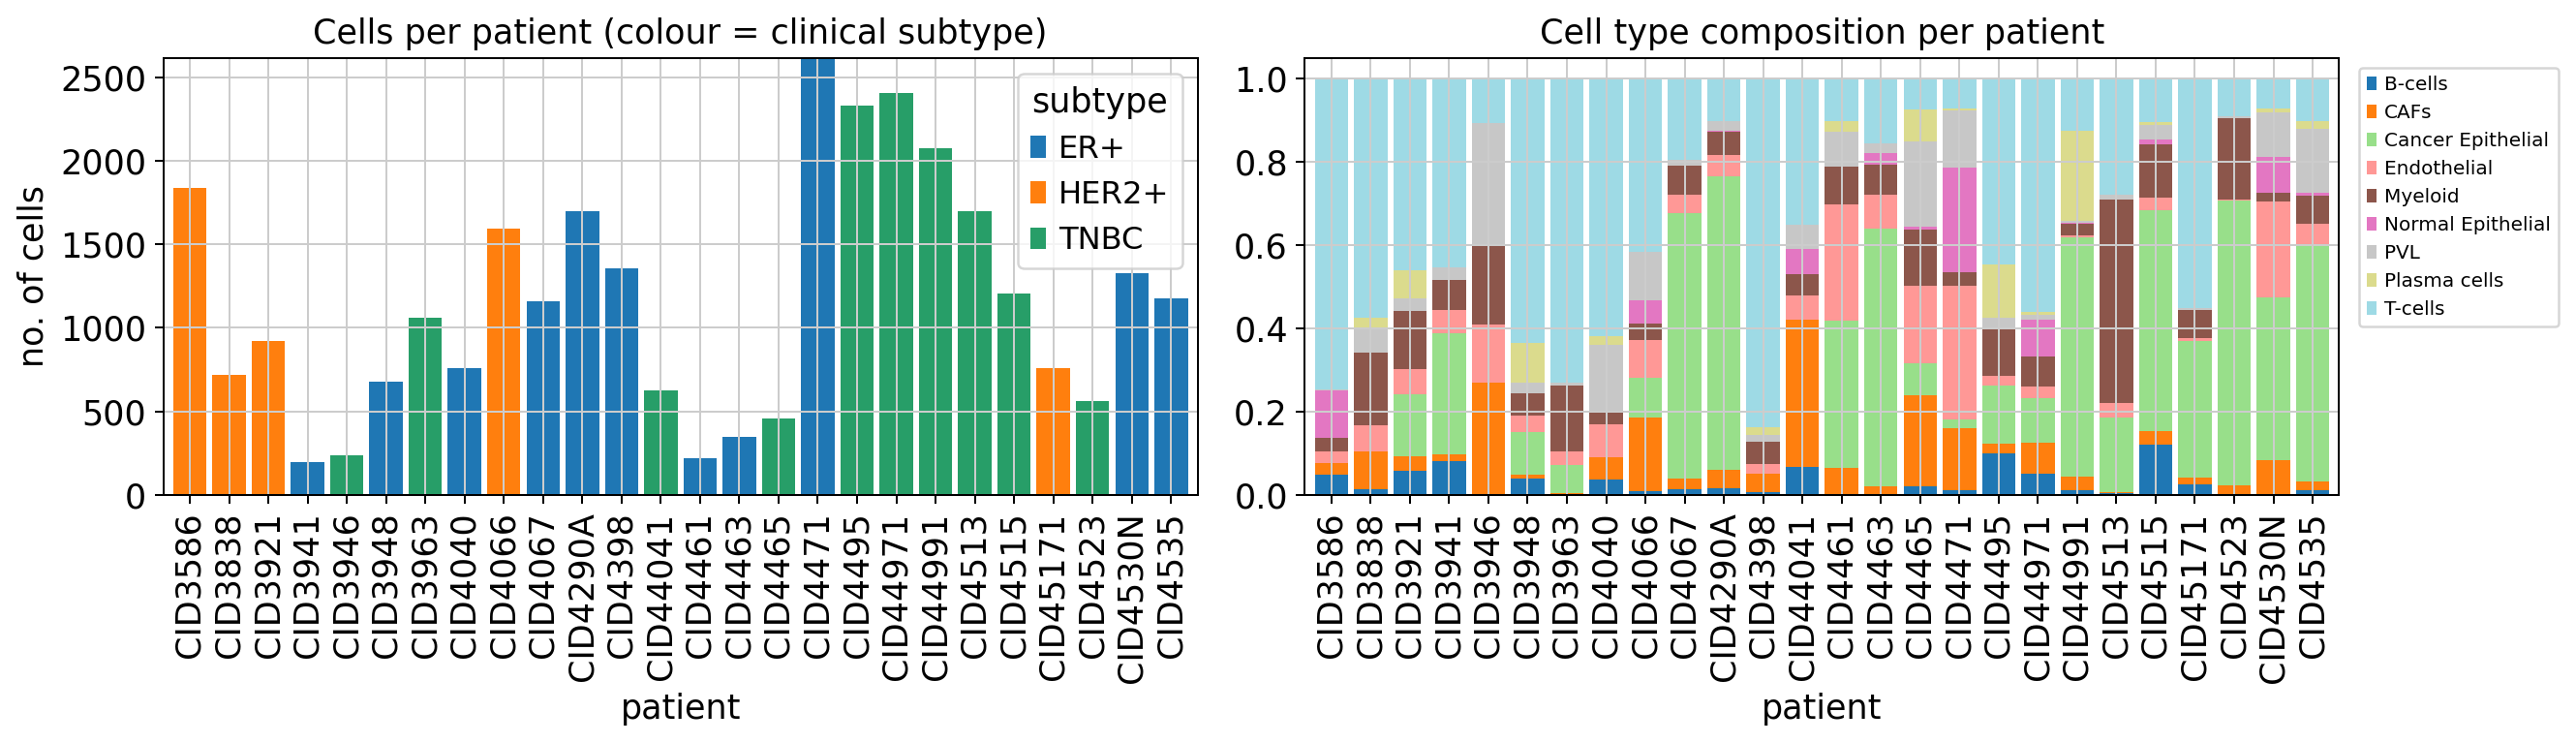

celltype
T-cells              10622
Cancer Epithelial     7360
Myeloid               2888
Endothelial           2268
CAFs                  1943
PVL                   1567
Normal Epithelial     1371
Plasma cells          1048
B-cells                933
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(adata.obs.groupby(["patient", "subtype"], observed=True).size().unstack(fill_value=0)
      .plot.bar(stacked=True, ax=axes[0], width=0.85))
axes[0].set_title("Cells per patient (colour = clinical subtype)"); axes[0].set_ylabel("no. of cells")

comp = pd.crosstab(adata.obs.patient, adata.obs.celltype, normalize="index")
comp.plot.bar(stacked=True, ax=axes[1], width=0.85, colormap="tab20", legend=False)
axes[1].set_title("Cell type composition per patient"); axes[1].legend(bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

print(adata.obs.celltype.value_counts())

**What we see:**
- The number of cells per patient is very uneven (from ~200 to ~2,600).
- There are 9 cell types. The most common are **T cells** (10,622) and **cancer epithelial cells** (7,360).
- The cell mix changes a lot between patients: in some samples most cells are tumour cells, while others are mostly T cells. This matters later, because differences between patients can come just from having different cell types.

**Why a count model?** If the data followed a Poisson distribution, the variance of each gene would be equal to its mean (red line). The plots below check this.

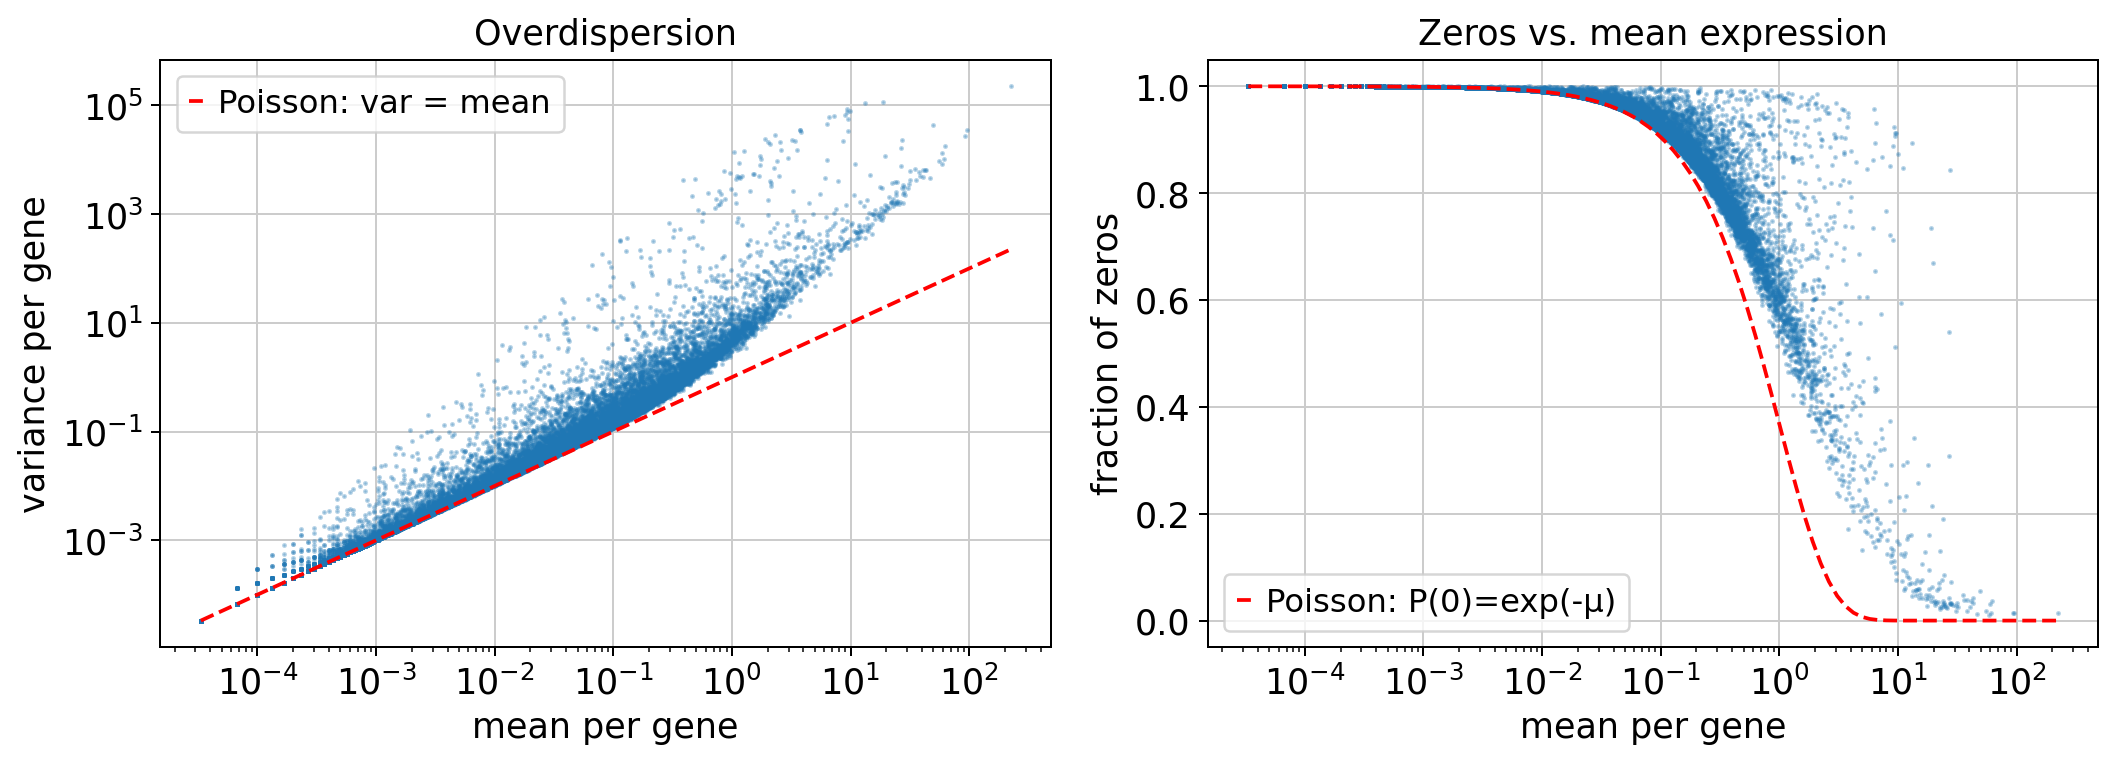

Overall sparsity: 93.8% zeros


In [ ]:
X = adata.X
mean = np.asarray(X.mean(0)).ravel()
mean_sq = np.asarray(X.multiply(X).mean(0)).ravel() if sp.issparse(X) else (X**2).mean(0)
var = mean_sq - mean**2
zero_frac = 1 - np.asarray((X > 0).mean(0)).ravel()
ok = mean > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(mean[ok], var[ok], ".", ms=2, alpha=0.3)
m = np.logspace(np.log10(mean[ok].min()), np.log10(mean[ok].max()), 100)
axes[0].loglog(m, m, "r--", label="Poisson: var = mean")
axes[0].set(xlabel="mean per gene", ylabel="variance per gene", title="Overdispersion"); axes[0].legend()

axes[1].semilogx(mean[ok], zero_frac[ok], ".", ms=2, alpha=0.3)
axes[1].semilogx(m, np.exp(-m), "r--", label="Poisson: P(0)=exp(-μ)")
axes[1].set(xlabel="mean per gene", ylabel="fraction of zeros", title="Zeros vs. mean expression"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Overall sparsity: {1 - X.nnz / np.prod(X.shape):.1%} zeros")

**What we see:**
- **93.8% of the values are zeros.**
- **Left:** almost all genes are above the red line, so the variance is much larger than the mean (**overdispersion**). Poisson can't capture this, but a **negative binomial (NB)** can.
- **Right:** genes have more zeros than Poisson predicts. This doesn't automatically mean we need an extra "zero-inflation" term (ZINB): overdispersion alone can produce extra zeros. We test this in section 7.

## 4. Preprocessing

- We keep the raw counts in `layers["counts"]` (this is what scVI uses).
- `X` is normalised and log-transformed (this is what PCA uses).
- We keep the **2,000 most variable genes** (HVGs).

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=10)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

try:
    sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3",
                                layer="counts", batch_key="patient", subset=True)
except Exception as e:  # patients with very few cells can make the loess fit fail
    print("Per-patient HVG selection failed, using global HVGs instead:", e)
    sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3", layer="counts", subset=True)
adata

Per-patient HVG selection failed, using global HVGs instead: b'reciprocal condition number  1.2231e-14'


AnnData object with n_obs × n_vars = 30000 × 2000
    obs: 'donor_id', 'percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_major', 'celltype_minor', 'celltype_subset', 'subtype', 'gene_module', 'calls', 'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed', 'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER', 'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67', 'subtype_by_IHC', 'treatment_status', 'treatment_details', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'disease_ontology_term_id', 'grade', 'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy', 'cell_type_ontology_term_id_legacy', 'celltype_major_legacy', 'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'patient', 'celltype', 'n_genes'
    var: 'cellrang

**Note:** we tried to choose HVGs per patient (`batch_key="patient"`), but it failed with a numerical error (some patients have very few cells), so the code automatically used HVGs computed on all cells together.

## 5. PCA vs. scVI

First we compute PCA with 10 components (same size as the scVI latent space, so the comparison is fair). Then we train three scVI models, each one changing **one thing**:

| model | corrects for patient? | distribution | question |
|---|---|---|---|
| `scvi_nb_nobatch` | no | NB | (a) |
| `scvi_nb_patient` | yes | NB | (a) |
| `scvi_zinb_patient` | yes | ZINB | (e) |

In [ ]:
tmp = adata.copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=N_LATENT, random_state=SEED)
adata.obsm["X_pca"] = tmp.obsm["X_pca"]
del tmp

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [ ]:
EXPERIMENTS = {
    "scvi_nb_nobatch":   dict(batch_key=None,      gene_likelihood="nb"),
    "scvi_nb_patient":   dict(batch_key="patient", gene_likelihood="nb"),
    "scvi_zinb_patient": dict(batch_key="patient", gene_likelihood="zinb"),
}

def train_scvi(adata, name, batch_key, gene_likelihood, n_latent=N_LATENT, **model_kwargs):
    a = adata.copy()                      # each model gets its own AnnData registration
    scvi.model.SCVI.setup_anndata(a, layer="counts", batch_key=batch_key)
    path = MODELS_DIR / name
    if path.exists() and not RETRAIN:
        model = scvi.model.SCVI.load(path, adata=a)
    else:
        model = scvi.model.SCVI(a, n_latent=n_latent, gene_likelihood=gene_likelihood, **model_kwargs)
        model.train(max_epochs=MAX_EPOCHS, early_stopping=True, check_val_every_n_epoch=1)
        model.save(path, overwrite=True)
    return model, a

MODELS = {}
for name, cfg in EXPERIMENTS.items():
    print(f"── {name} ──")
    model, a = train_scvi(adata, name, **cfg)
    MODELS[name] = (model, a)
    adata.obsm[f"X_{name}"] = model.get_latent_representation(a)

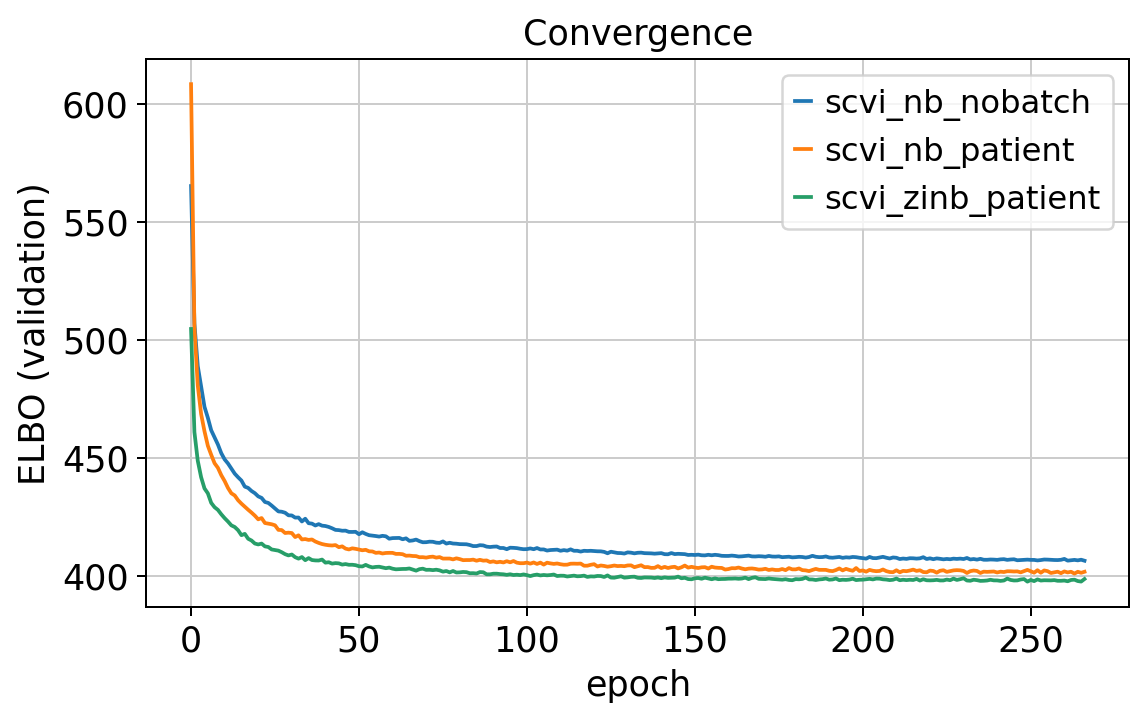

In [ ]:
# Training curves: validation ELBO (has it converged? is it overfitting?)
fig, ax = plt.subplots(figsize=(7, 4))
for name, (model, _) in MODELS.items():
    h = model.history
    if "elbo_validation" in h:
        ax.plot(h["elbo_validation"].values.ravel(), label=name)
ax.set(xlabel="epoch", ylabel="ELBO (validation)", title="Convergence"); ax.legend(); plt.show()

**What we see:** the three models trained for the full 267 epochs. The curves (here lower is better) drop quickly and are flat after ~150 epochs, so the models **converged**, and there is no sign of overfitting. ZINB ends slightly lower, but the difference is small.

## 6. Evaluating the latent space

We measure two things:

- **Are cell types kept apart?** We run k-means and compare the clusters with the real cell types (**ARI**, **NMI**), and we compute the **silhouette** score (ASW). Higher = better.
- **Are patients mixed?** For each cell we look at its 50 nearest neighbours and compute how mixed the patients are (**entropy**, 0 = all neighbours from the same patient, 1 = perfectly mixed).

We also compute the patient mixing **per cell type**. Immune and stromal cells are similar across patients, so they should mix. Tumour cells are different in every patient, so they should not necessarily mix.

In [ ]:
def batch_mixing_entropy(emb, batch, k=K_NEIGHBORS, n_sample=5_000, seed=SEED):
    # Normalised entropy of the batch composition among the k neighbours of each sampled cell.
    r = np.random.default_rng(seed)
    idx = r.choice(len(emb), size=min(n_sample, len(emb)), replace=False)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(emb)
    neigh = nn.kneighbors(emb[idx], return_distance=False)[:, 1:]
    codes = pd.Categorical(batch).codes
    n_b = codes.max() + 1
    counts = np.stack([np.bincount(row, minlength=n_b) for row in codes[neigh]])
    p = counts / k
    H = -(p * np.log(np.where(p > 0, p, 1))).sum(1) / np.log(n_b)
    return idx, H

def evaluate(adata, rep, label_key="celltype", batch_key="patient", n_sil=5_000):
    emb = adata.obsm[rep]
    labels = adata.obs[label_key].values
    k = adata.obs[label_key].nunique()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(emb)
    r = np.random.default_rng(SEED)
    sub = r.choice(len(emb), size=min(n_sil, len(emb)), replace=False)
    idx, H = batch_mixing_entropy(emb, adata.obs[batch_key].values)
    summary = dict(
        ARI=adjusted_rand_score(labels, km),
        NMI=normalized_mutual_info_score(labels, km),
        ASW_celltype=(silhouette_score(emb[sub], labels[sub]) + 1) / 2,
        batch_entropy=H.mean(),
    )
    per_type = pd.Series(H).groupby(adata.obs[label_key].values[idx]).mean()
    return summary, per_type

REPS = ["X_pca"] + [f"X_{n}" for n in EXPERIMENTS]
summaries, per_type = {}, {}
for rep in REPS:
    summaries[rep], per_type[rep] = evaluate(adata, rep)

results = pd.DataFrame(summaries).T.round(3)
results.to_csv(RESULTS_DIR / "01_latent_metrics.csv")
results

,ARI,NMI,ASW_celltype,batch_entropy
X_pca,0.648,0.713,0.642,0.393
X_scvi_nb_nobatch,0.560,0.745,0.589,0.263
X_scvi_nb_patient,0.637,0.801,0.613,0.493
X_scvi_zinb_patient,0.633,0.795,0.604,0.505


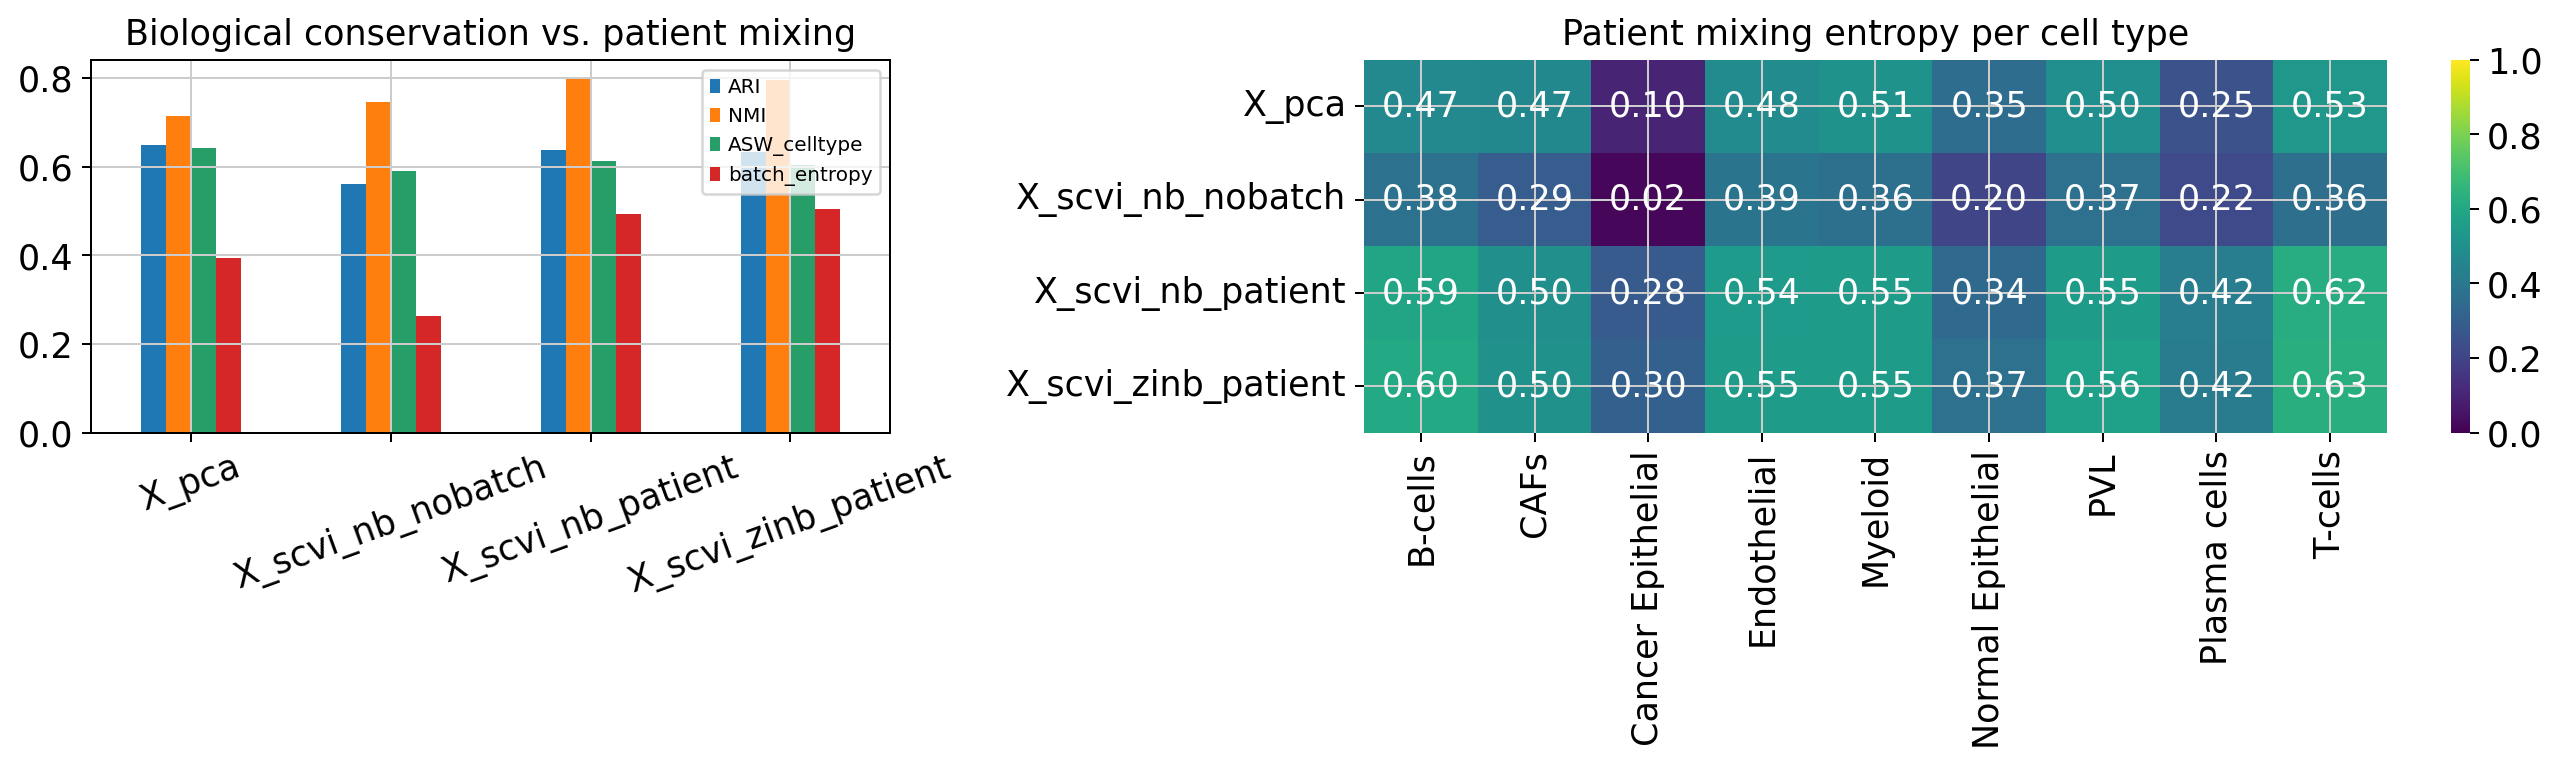

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
results.plot.bar(ax=axes[0], rot=20); axes[0].set_title("Biological conservation vs. patient mixing")
axes[0].legend(fontsize=8)

pt = pd.DataFrame(per_type).T
sns.heatmap(pt, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Patient mixing entropy per cell type")
plt.tight_layout(); plt.show()

### Results (question a)

**Overall metrics:**
- All methods separate cell types reasonably well (ARI 0.56–0.65, NMI 0.71–0.80). PCA has the best ARI (0.65) and scVI with patient correction has the best NMI (0.80).
- Correcting for patient clearly increases mixing: entropy goes from **0.26** (scVI without correction) to **~0.50** (scVI with correction).
- NB and ZINB give almost the same numbers.

**Per cell type (heatmap):**
- **Cancer Epithelial has by far the lowest mixing** in every model: 0.02 without correction, 0.10 with PCA and only ~0.29 with correction. Even after correction, tumour cells still group by patient.
- Immune and stromal cells (T cells, B cells, myeloid, endothelial, PVL) mix much more, reaching ~0.55–0.63 with correction.

**Conclusion:** most of the patient effect in tumour cells is real biology, not technical noise. The correction pulls tumours a bit closer together (0.02 → 0.28), so it can hide some real differences. So:
- to **annotate cell types**, correcting for patient is useful;
- to **compare patients or tumours**, it's safer not to correct (or to use a model that keeps the patient information, like MrVI).

## 7. Does the model generate realistic data? (question e)

We take 3,000 cells, ask each model to **generate new data** for them, and compare the fake data with the real data gene by gene: mean, variance and fraction of zeros. If the model is good, the points fall on the red diagonal.

We compare:
- **Poisson (baseline):** a very simple model with no cell structure.
- **scVI-NB** and **scVI-ZINB**.

In [ ]:
def gene_stats(X, var_names):
    X = to_dense(X).astype(float)
    return pd.DataFrame(dict(mean=X.mean(0), var=X.var(0), zero_frac=(X == 0).mean(0)), index=var_names)

def ppc(model, a, idx):
    sim = to_dense(model.posterior_predictive_sample(a, indices=idx, n_samples=1))
    if sim.ndim == 3:
        sim = sim[..., 0]
    return gene_stats(sim, a.var_names)

N_PPC = 3_000
idx_ppc = np.sort(rng.choice(adata.n_obs, size=min(N_PPC, adata.n_obs), replace=False))
obs_counts = to_dense(adata.layers["counts"][idx_ppc]).astype(float)
observed = gene_stats(obs_counts, adata.var_names)

L = obs_counts.sum(1, keepdims=True)
p_g = obs_counts.sum(0, keepdims=True) / obs_counts.sum()
simulated = {"poisson_null": gene_stats(rng.poisson(L * p_g), adata.var_names)}
for name in ["scvi_nb_patient", "scvi_zinb_patient"]:
    model, a = MODELS[name]
    simulated[name] = ppc(model, a, idx_ppc)

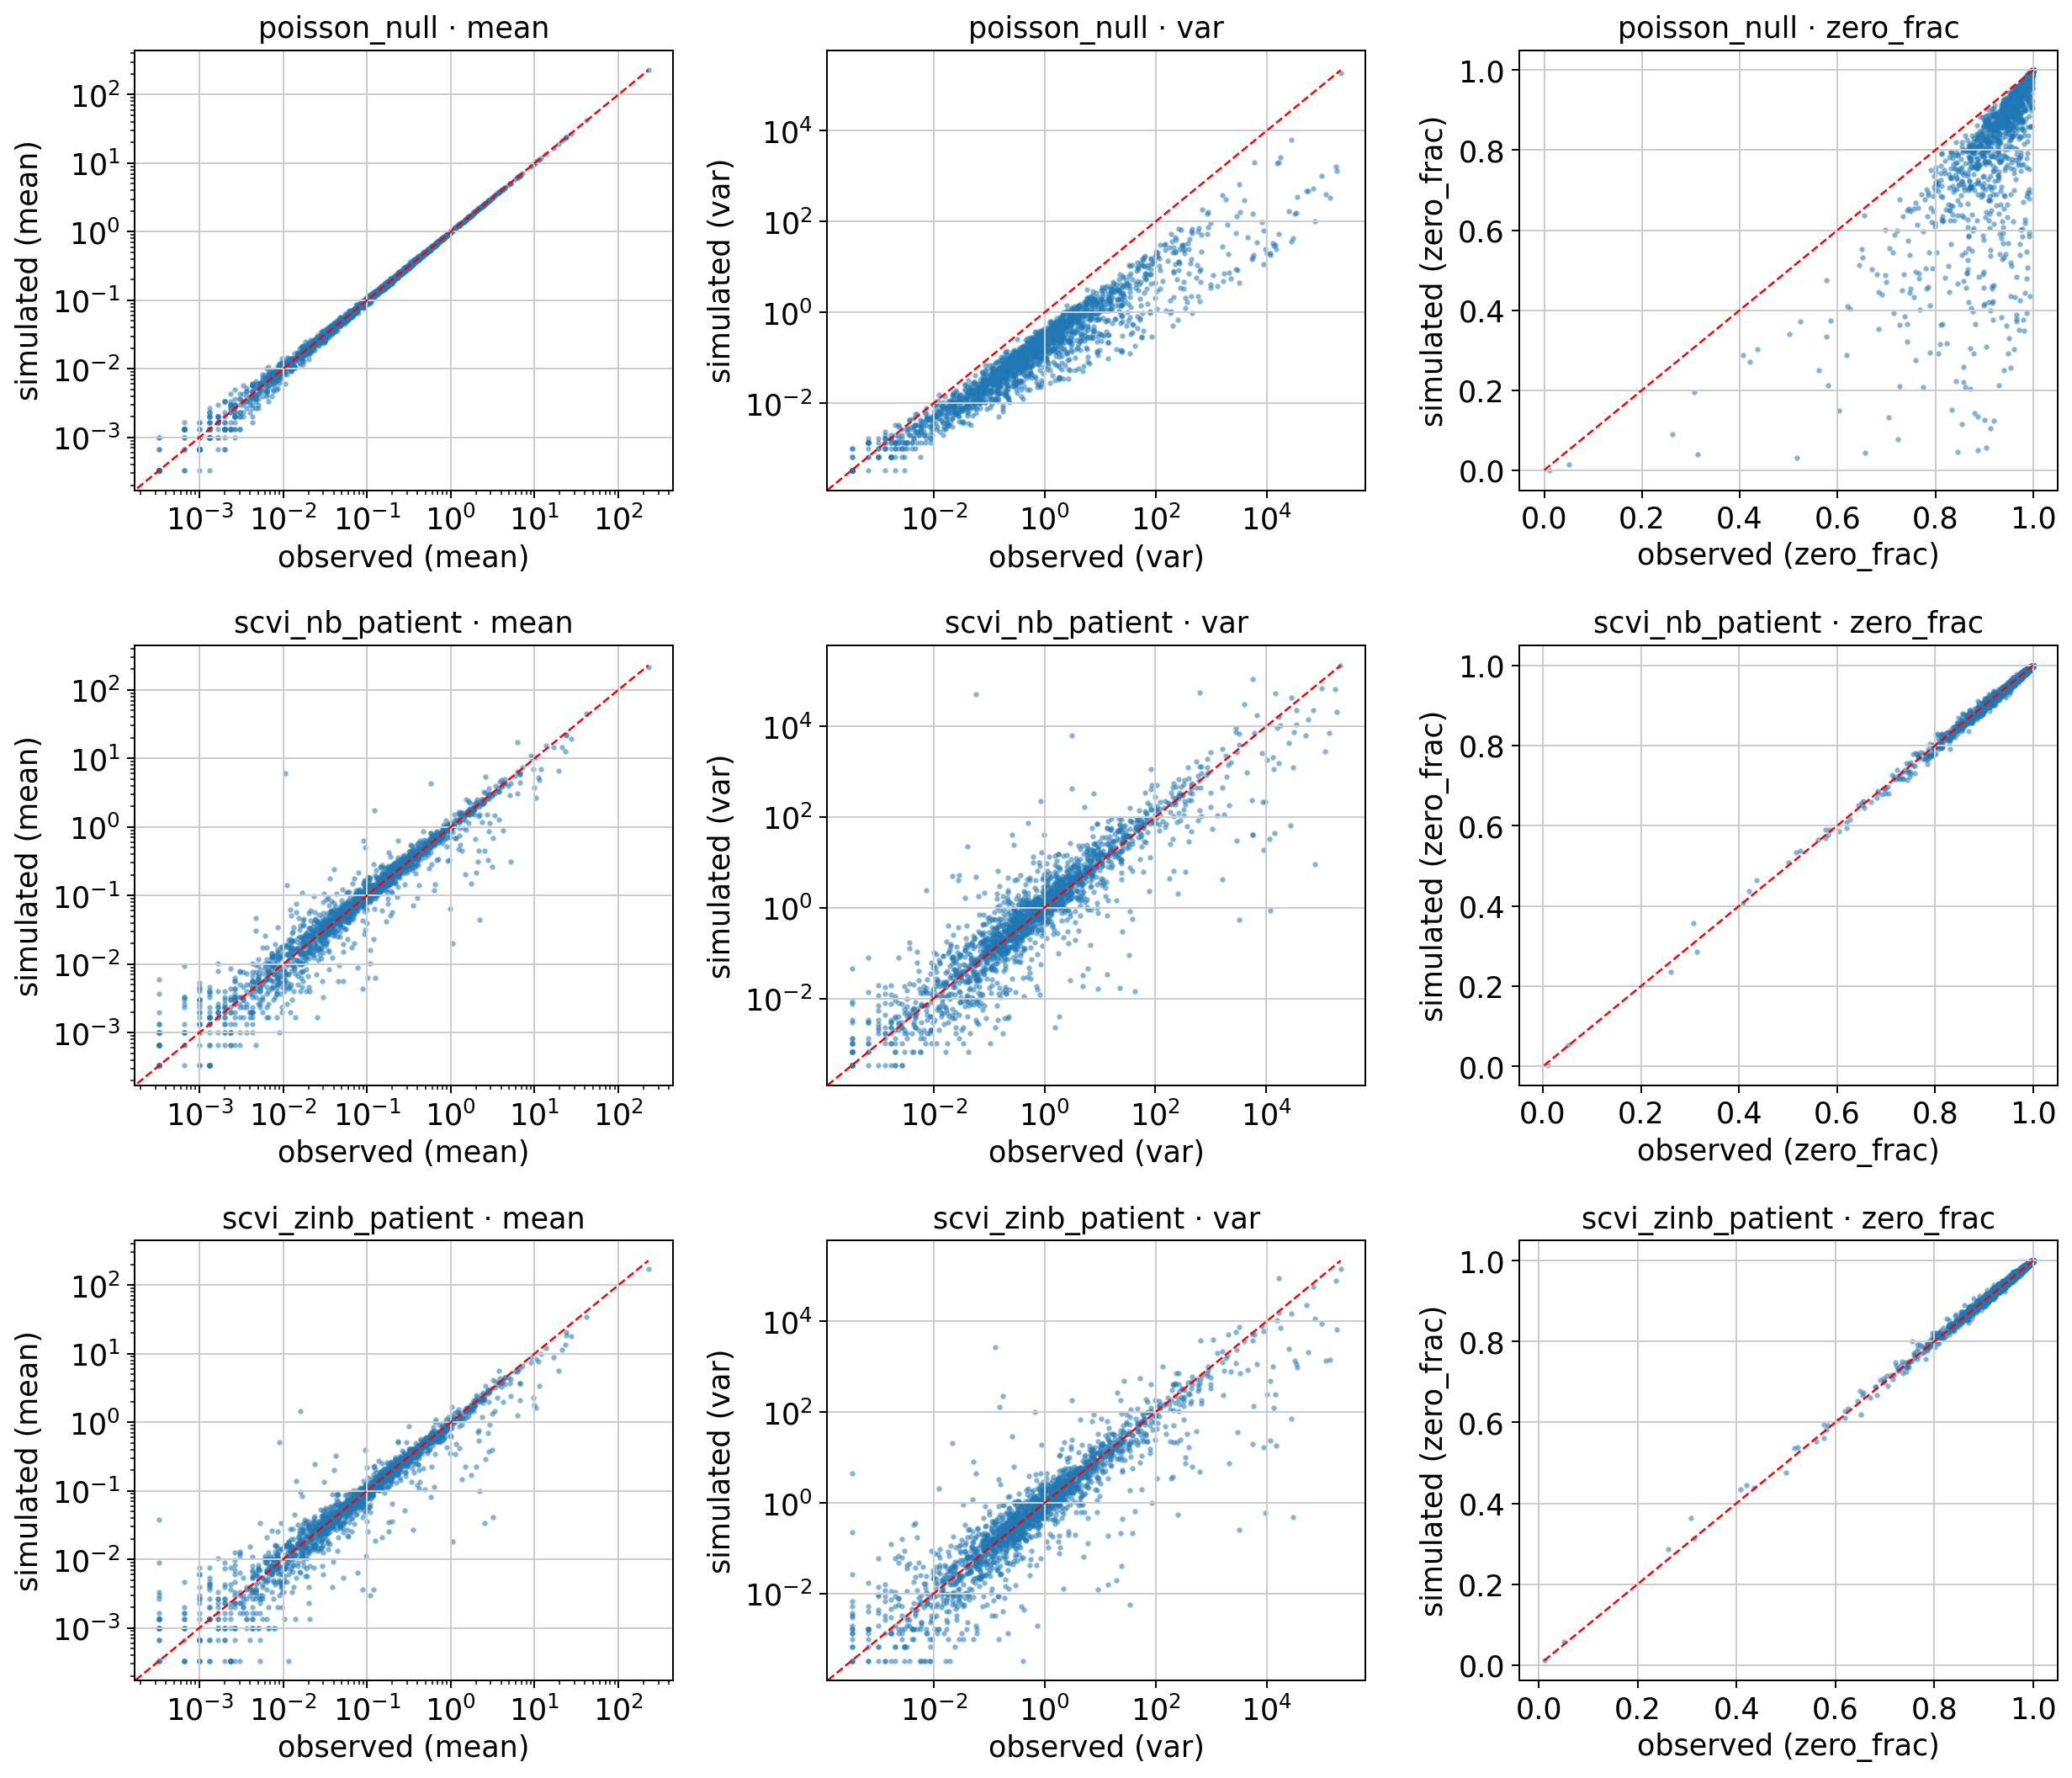

,MAE log10(mean),MAE log10(var),MAE zero_frac
poisson_null,0.0612,0.7676,0.0814
scvi_nb_patient,0.1961,0.4422,0.0041
scvi_zinb_patient,0.2076,0.4266,0.0037


In [ ]:
stats = ["mean", "var", "zero_frac"]
fig, axes = plt.subplots(len(simulated), 3, figsize=(14, 4 * len(simulated)))
for i, (name, simdf) in enumerate(simulated.items()):
    for j, s in enumerate(stats):
        ax = axes[i, j]
        x, y = observed[s].values, simdf[s].values
        ax.scatter(x, y, s=3, alpha=0.4)
        lo, hi = np.nanmin([x, y]), np.nanmax([x, y])
        ax.plot([lo, hi], [lo, hi], "r--", lw=1)
        if s != "zero_frac":
            ax.set_xscale("log"); ax.set_yscale("log")
        ax.set(xlabel=f"observed ({s})", ylabel=f"simulated ({s})", title=f"{name} · {s}")
plt.tight_layout(); plt.show()

def ppc_error(obs, sim):
    eps = 1e-8
    return pd.Series({
        "MAE log10(mean)": np.mean(np.abs(np.log10(sim["mean"] + eps) - np.log10(obs["mean"] + eps))),
        "MAE log10(var)":  np.mean(np.abs(np.log10(sim["var"] + eps) - np.log10(obs["var"] + eps))),
        "MAE zero_frac":   np.mean(np.abs(sim["zero_frac"] - obs["zero_frac"])),
    })

ppc_table = pd.DataFrame({n: ppc_error(observed, s) for n, s in simulated.items()}).T.round(4)
ppc_table.to_csv(RESULTS_DIR / "01_ppc_errors.csv")
ppc_table

### Results (question e)

| model | error in mean | error in variance | error in % zeros |
|---|---|---|---|
| Poisson | **0.06** | 0.77 | 0.081 |
| scVI-NB | 0.20 | 0.44 | 0.0041 |
| scVI-ZINB | 0.21 | **0.43** | **0.0037** |

- **Poisson** gets the mean right, but it **underestimates the variance** (points below the diagonal) and also predicts **too few zeros**. So Poisson is not a good model for this data.
- **scVI** fixes both problems: the variance is much closer to the real one and the fraction of zeros is almost perfect. The mean is a bit noisier than with Poisson, because we only generate one sample per cell.
- **NB and ZINB are practically the same** (0.0041 vs 0.0037 error in zeros). This agrees with the paper: the zero-inflation part is not needed, and NB already explains the zeros. This is also why scvi-tools uses NB by default.

## 8. UMAP

UMAP is only a picture: distances and cluster sizes in it are not reliable. The real evidence is in section 6. We compare scVI **without** and **with** patient correction.

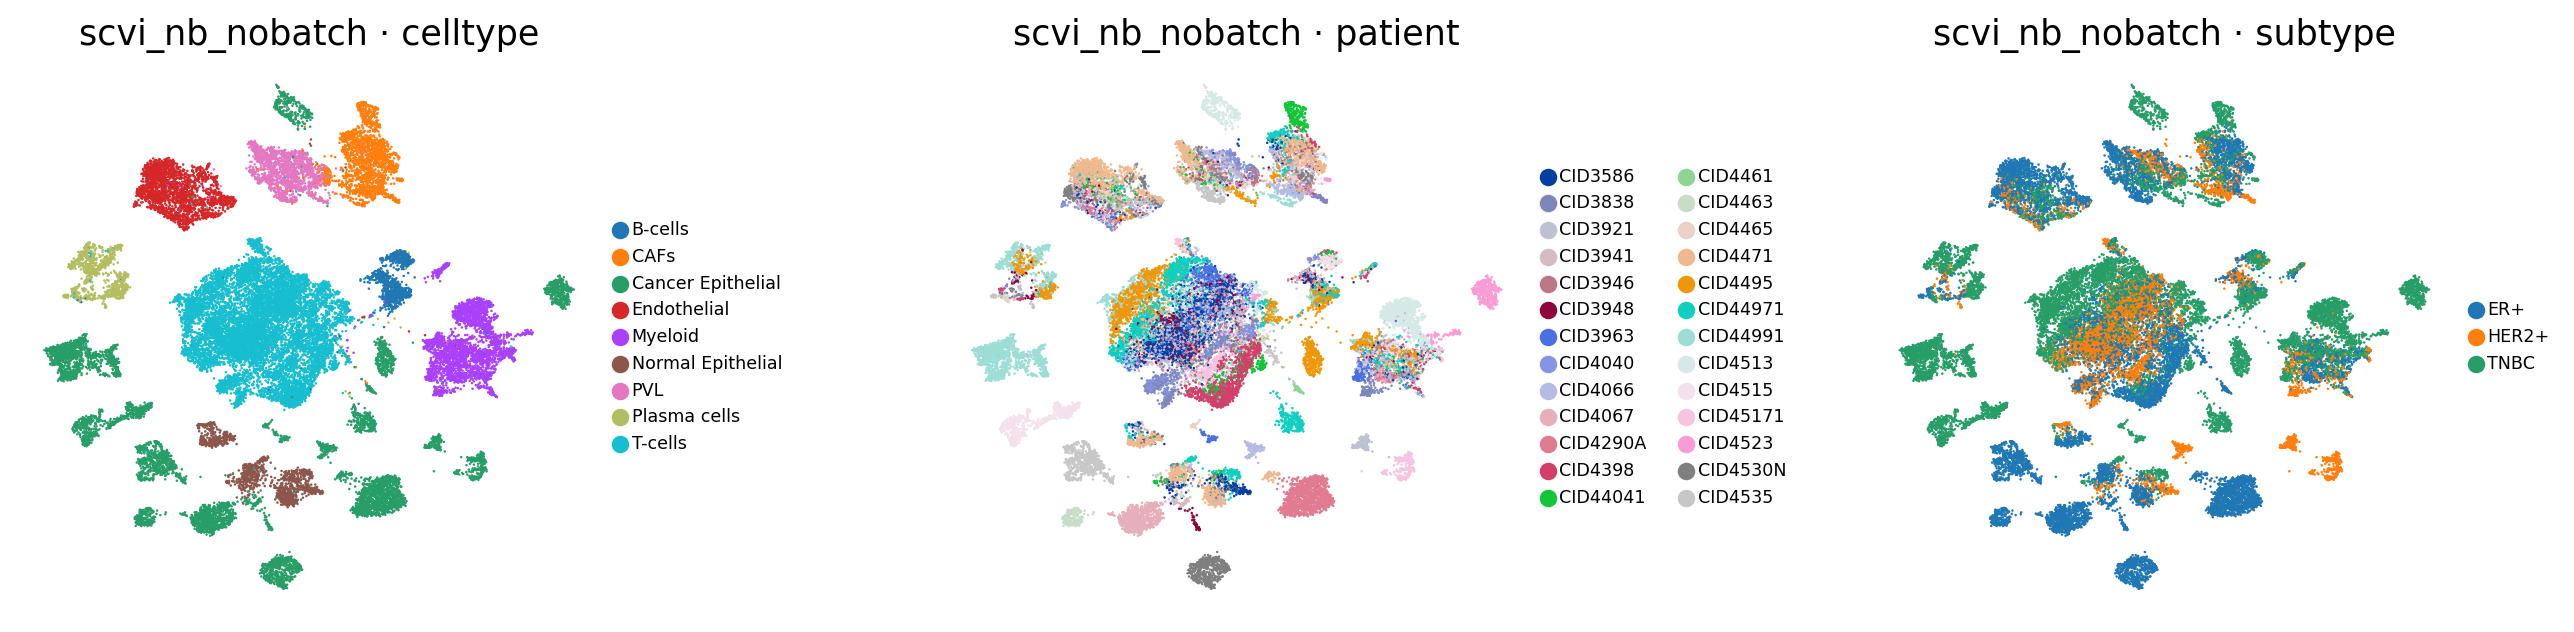

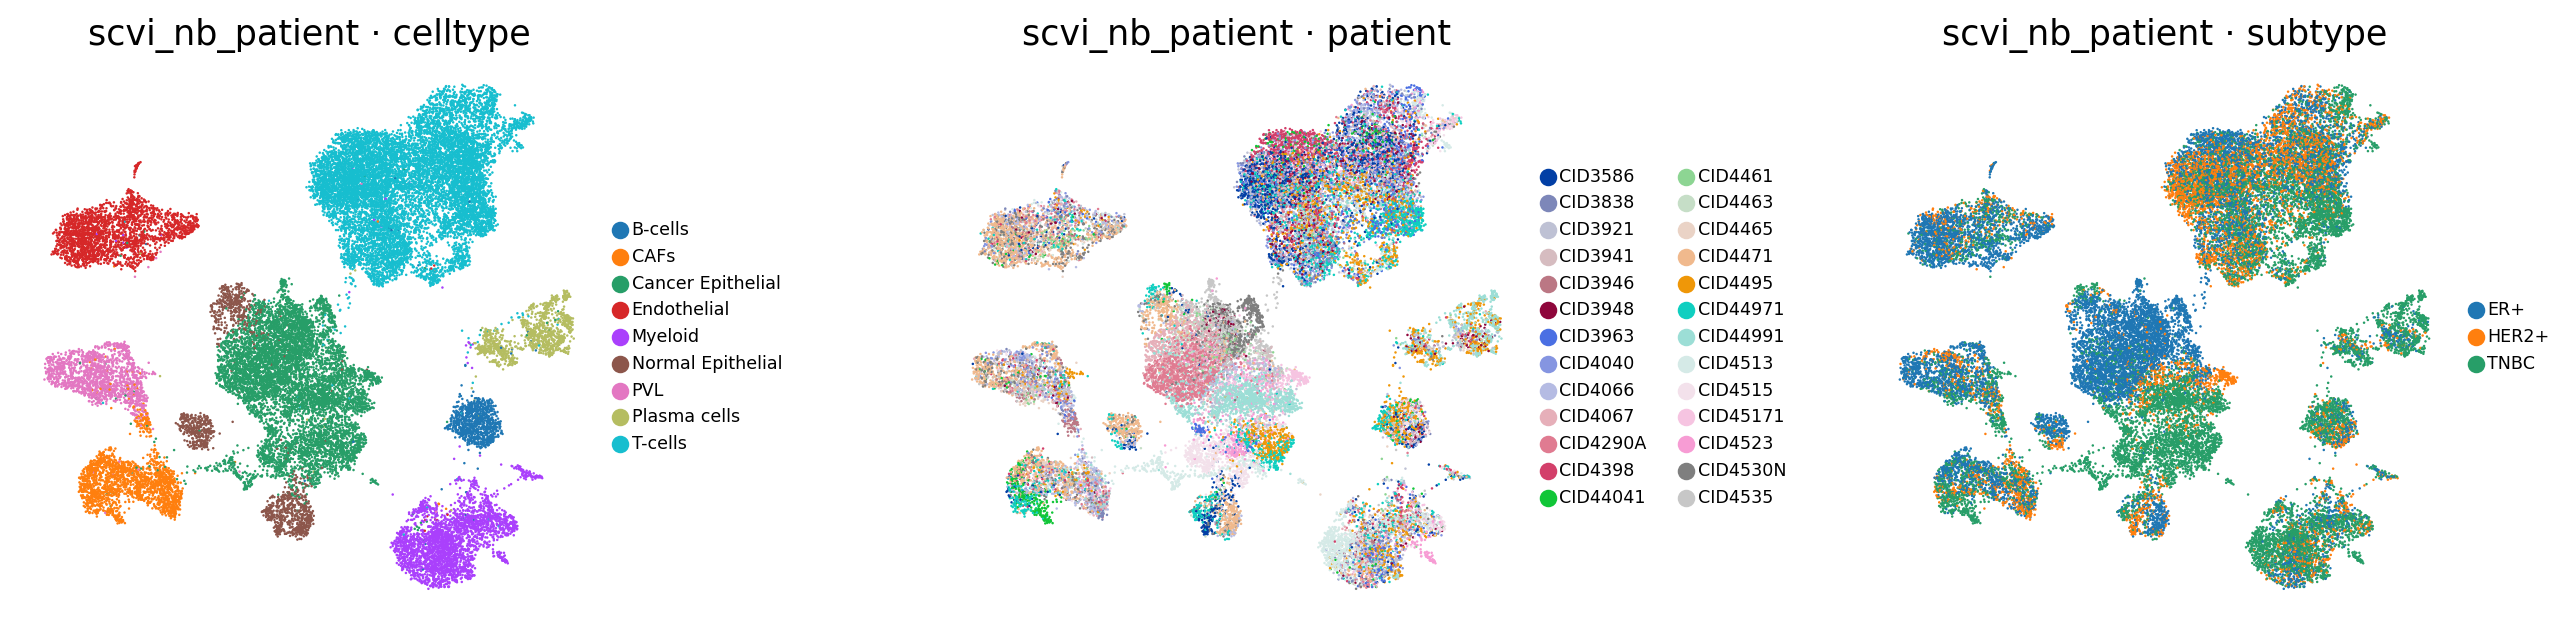

In [ ]:
for name in ["scvi_nb_nobatch", "scvi_nb_patient"]:
    sc.pp.neighbors(adata, use_rep=f"X_{name}", random_state=SEED)
    sc.tl.umap(adata, random_state=SEED)
    adata.obsm[f"X_umap_{name}"] = adata.obsm["X_umap"].copy()
    sc.pl.embedding(adata, basis=f"X_umap_{name}", color=["celltype", "patient", "subtype"],
                    wspace=0.45, legend_fontsize=7, title=[f"{name} · {c}" for c in ["celltype", "patient", "subtype"]])

**What we see:**
- **Without correction (top row):** immune and stromal cells form clear groups, but **tumour cells split into many small islands, one per patient**.
- **With correction (bottom row):** patients are well mixed in T cells, myeloid cells and stromal cells. Tumour cells now form one big group, but inside it they are still **organised by subtype** (ER+ and TNBC in different areas).

This matches the numbers in section 6.

## 9. From cells to patients (question c, first look)

The simplest way to describe a patient is by the **percentage of each cell type** in their sample. Do patients of the same subtype look alike with just this?

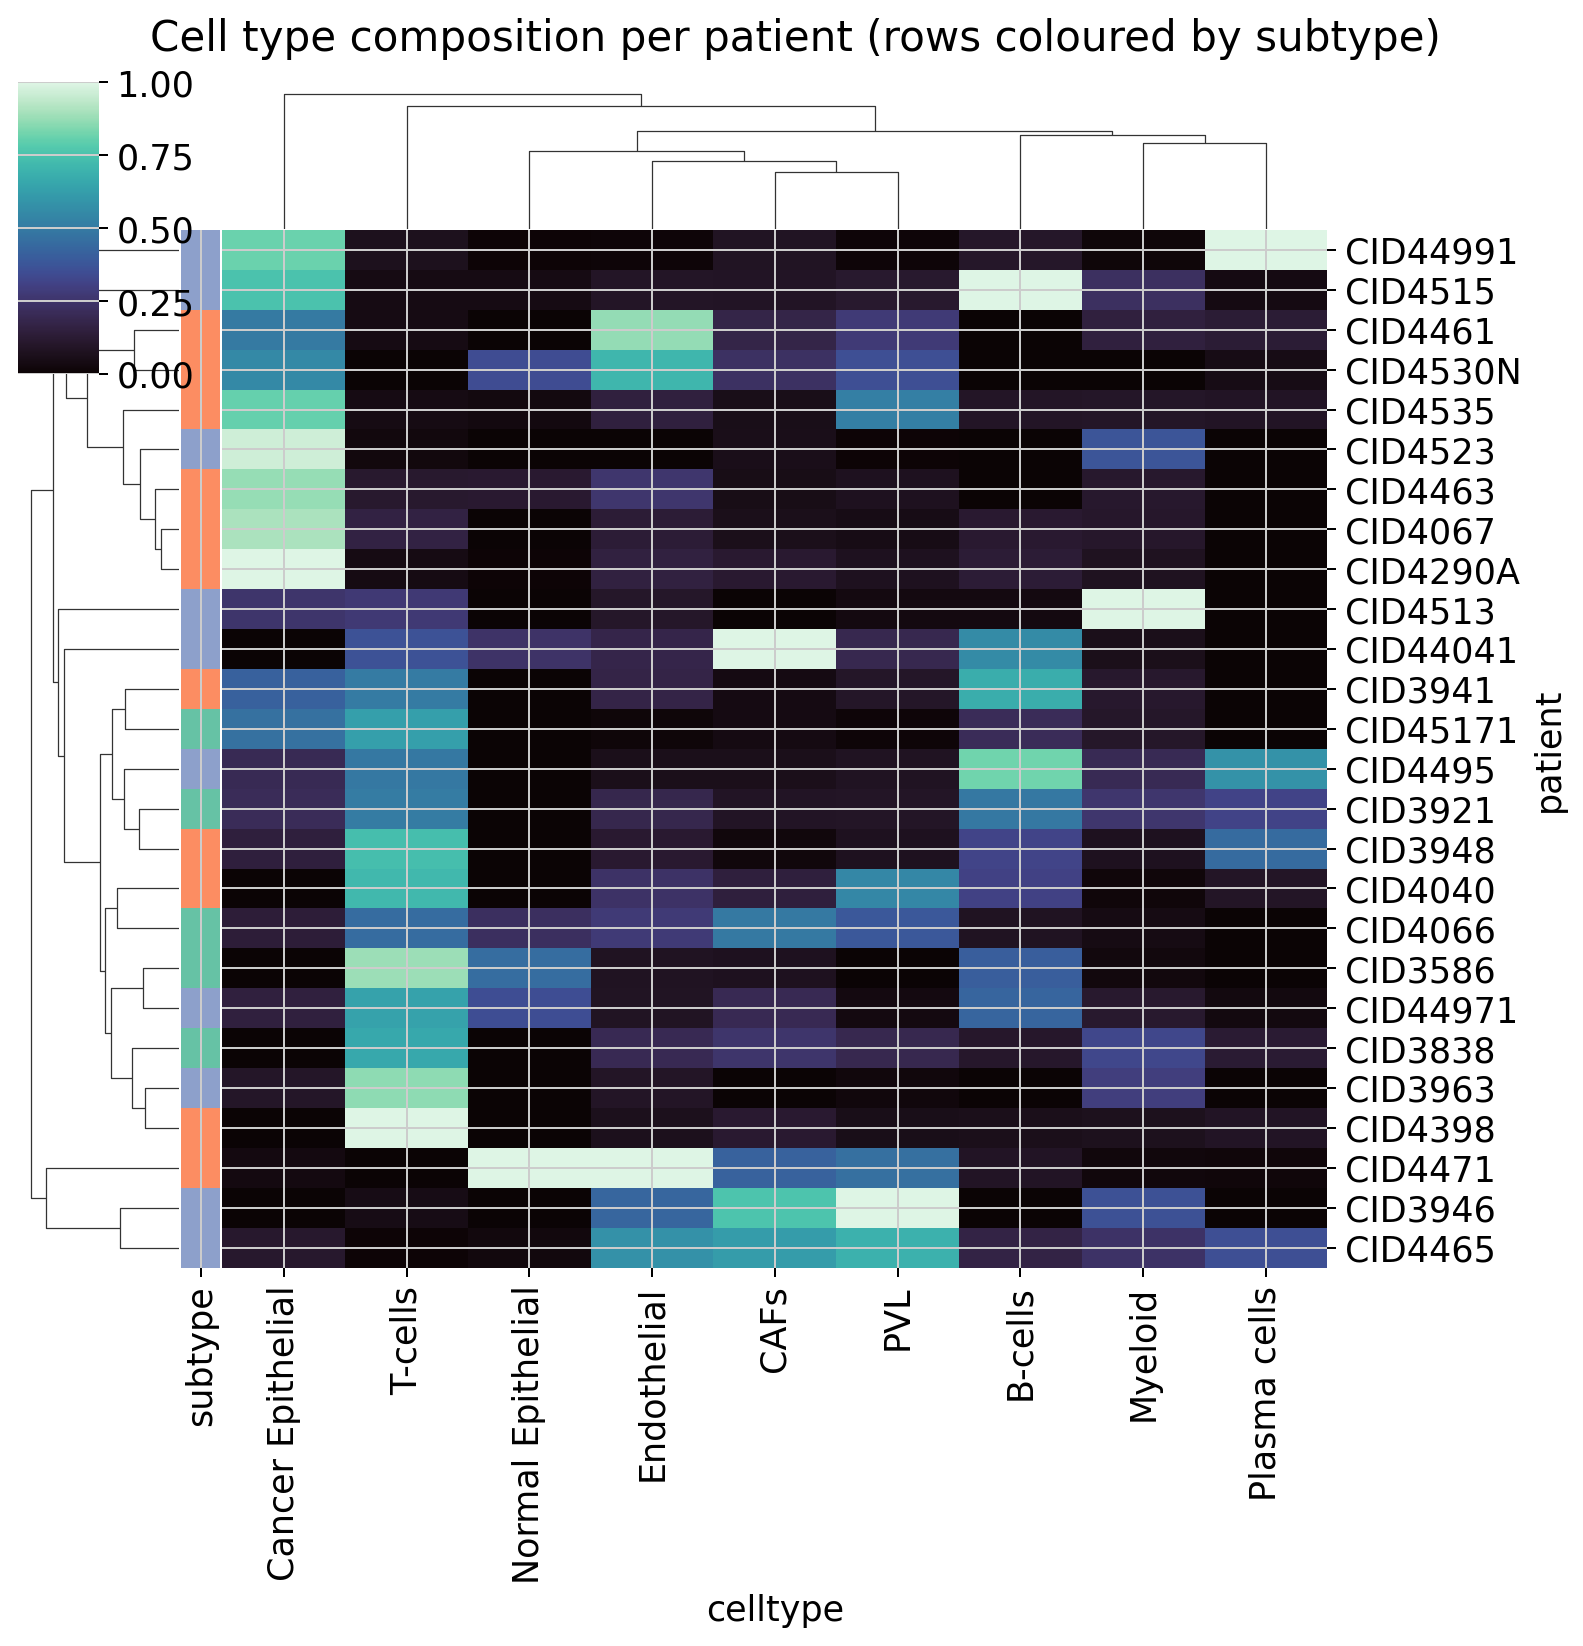

In [ ]:
comp = pd.crosstab(adata.obs.patient, adata.obs.celltype, normalize="index")
subtype_of = adata.obs.groupby("patient", observed=True).subtype.first()
pal = dict(zip(subtype_of.unique(), sns.color_palette("Set2", subtype_of.nunique())))
# Convert subtype_of to string to avoid pandas Categorical.map MultiIndex bug
row_colors = subtype_of.astype(str).map(pal)
g = sns.clustermap(comp, cmap="mako", row_colors=row_colors, figsize=(9, 9),
                   standard_scale=1, dendrogram_ratio=0.12)
g.fig.suptitle("Cell type composition per patient (rows coloured by subtype)", y=1.02)
plt.show()

**What we see** (row colours: orange = ER+, green = HER2+, purple = TNBC):
- Patients split into two main groups: **tumour-rich** samples (top) and **immune-rich** samples (mostly T cells, bottom).
- The subtypes are **mixed** in both groups. For example, the tumour-rich group has both ER+ and TNBC patients, and the HER2+ patients are spread across the immune-rich group.

So cell composition alone is **not enough** to tell subtypes apart.

## 10. Saving the results

In [ ]:
out = adata.copy()
# Resolve the name clash by resetting the var index name
if out.var.index.name == "feature_name":
    out.var.index.name = None

out.write_h5ad(RESULTS_DIR / "01_wu2021_latents.h5ad", compression="gzip")
print("Saved:", sorted(p.name for p in RESULTS_DIR.iterdir()))

Saved: ['01_latent_metrics.csv', '01_ppc_errors.csv', '01_wu2021_latents.h5ad']


## 11. Summary

**What we found**
- The data is very sparse (94% zeros) and overdispersed, so Poisson is not enough. A **negative binomial (NB)** works well, and **ZINB adds nothing** on top of it.
- PCA and scVI both separate cell types well. Correcting for patient doubles the patient mixing (0.26 -> 0.50).
- **Tumour cells stay patient-specific** even after correction, while immune and stromal cells mix well. The patient effect in tumours is mostly real biology.
- Cell type composition alone does **not** clearly separate the clinical subtypes.
